# Interim Report

Using the Hestay JT128 LiDAR sensor, I recorded several files, in different environments. 
There are limitations on where data can be recorded as the sensor must be connected to a power source and a computer through an ethernet connection at all times in order to record data.




In [3]:
# Import libraries

import numpy as np
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
from sklearn.cluster import SpectralClustering
from sklearn.cluster import KMeans
import hdbscan

In [4]:

def load_pcd(file_path):
    with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
        header = []
        data_type = None
        fields = None

        for line in f:
            stripped = line.strip()
            if not stripped or stripped.startswith("#"):
                continue
            header.append(stripped)
            if stripped.startswith("DATA"):
                parts = stripped.split()
                if len(parts) < 2:
                    raise ValueError("Invalid PCD DATA line")
                data_type = parts[1].lower()
                break
            if stripped.startswith("FIELDS"):
                fields = stripped.split()[1:]

        if data_type != "ascii":
            raise ValueError("Only ASCII PCD files are supported")

        rows = []
        for line in f:
            stripped = line.strip()
            if not stripped or stripped.startswith("#"):
                continue
            values = stripped.replace(",", " ").split()
            if values:
                rows.append([float(value) for value in values])

        if not rows:
            raise ValueError("No point data found in PCD file")

        data = np.array(rows, dtype=float)
        if data.ndim == 1:
            data = data.reshape(1, -1)

        if fields is not None:
            field_map = {name: idx for idx, name in enumerate(fields)}
            if all(key in field_map for key in ("x", "y", "z")):
                points = data[:, [field_map["x"], field_map["y"], field_map["z"]]]
            else:
                points = data[:, :3]
        else:
            points = data[:, :3]

        return points





In [5]:
def cluster_points(points, eps=0.05, min_samples=10):
    clustering = DBSCAN(eps=eps, min_samples=min_samples)
    labels = clustering.fit_predict(points)
    return labels


def cluster_points_hdbscan(points, min_cluster_size=10, min_samples=None):
    
    clustering = hdbscan.HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=min_samples,
    )
    labels = clustering.fit_predict(points)
    return labels

In [6]:


def cluster_points_kmeans(points, n_clusters=10, random_state=42):
    clustering = KMeans(
        n_clusters=n_clusters,
        random_state=random_state,
        n_init="auto"
    )
    labels = clustering.fit_predict(points)
    return labels

In [7]:


def cluster_points_spectral(points, n_clusters=10, random_state=42):
    clustering = SpectralClustering(
        n_clusters=n_clusters,
        affinity="nearest_neighbors",
        assign_labels="kmeans",
        random_state=random_state
    )
    labels = clustering.fit_predict(points)
    return labels

In [8]:
import ipympl

def plot_clusters(points, labels, title):

    # to interact  with plot
    %matplotlib widget


    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")
    unique_labels = np.unique(labels)
    cmap = plt.cm.get_cmap("tab20", len(unique_labels))

    for idx, label in enumerate(unique_labels):
        mask = labels == label
        if label == -1:
            color = "k"
            label_name = "noise"
            size = 2
        else:
            color = cmap(idx)
            label_name = f"cluster {label}"
            size = 4

        ax.scatter(
            points[mask, 0],
            points[mask, 1],
            points[mask, 2],
            c=[color],
            s=size,
            label=label_name,
            depthshade=True,
        )

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    # ax.legend(loc="best", fontsize="small")
    plt.title(title)
    plt.tight_layout()
    plt.show()



In [9]:
def filter(points, threshold):
    
    distances = np.linalg.norm(points, axis=1)
    threshold_number = threshold * distances.max()

    # Filter points
    mask = distances <= threshold_number
    filtered_points = points[mask]

    return filtered_points


In [10]:
def subsample(points, keep_fraction):
    if not 0 < keep_fraction <= 1:
        raise ValueError("keep_fraction must be between 0 and 1")

    num_keep = max(1, int(len(points) * keep_fraction))

    indices = np.linspace(
        0,
        len(points) - 1,
        num_keep,
        dtype=int
    )

    return points[indices]

In [11]:
def main( pcd_file,cluster = "DBSCAN", threshold = 0.1, eps = 0.05, min_samples = 10, keep_fraction = 0.8):

    points = load_pcd(pcd_file)
    points = filter(points, threshold)
    points = subsample(points, keep_fraction)
    if cluster == "DBSCAN":
        labels = cluster_points(points, eps=eps, min_samples=min_samples)

    elif cluster == "KMEANS":
        labels = cluster_points_kmeans(points, n_clusters = 3)
    elif cluster == "Spectral":
        labels = cluster_points_spectral(points)
    elif cluster == "HDBSCAN":
        labels = cluster_points_hdbscan(points, min_cluster_size=min_samples)

    plot_clusters(points, labels, cluster)


C:\Users\danag\AppData\Local\Temp\ipykernel_3884\2928612373.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", len(unique_labels))


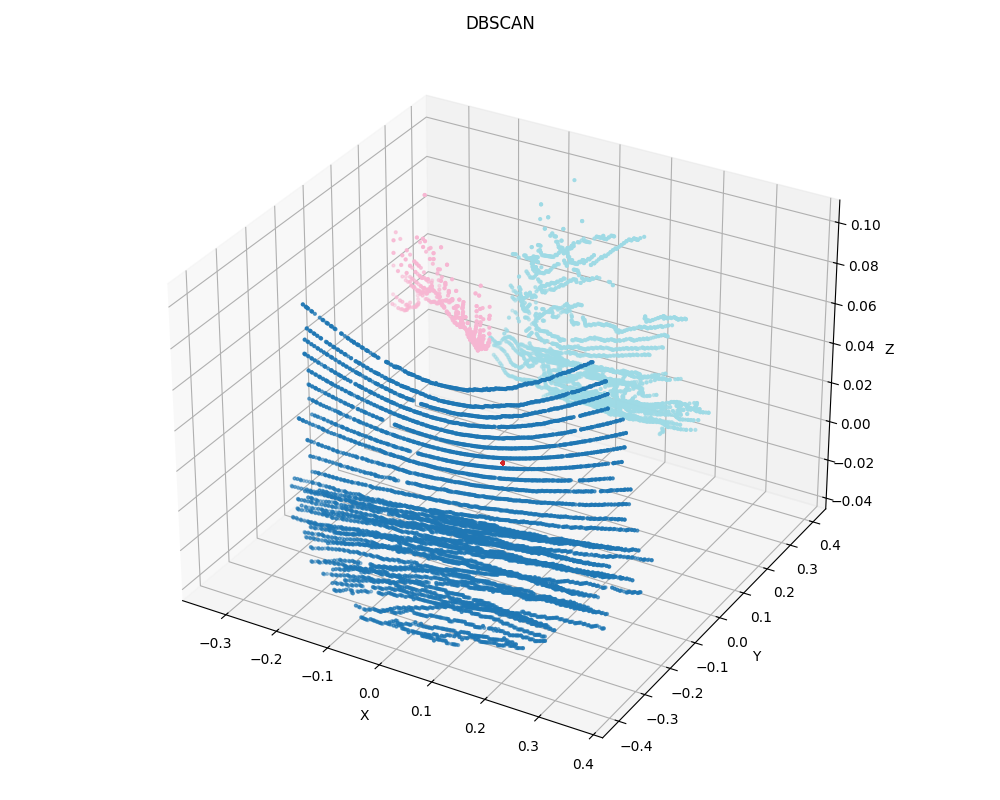

In [12]:
main(pcd_file = r"C:\Users\danag\Documents\LIDAR\data\test1.pcd")

C:\Users\danag\AppData\Local\Temp\ipykernel_3884\2928612373.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", len(unique_labels))


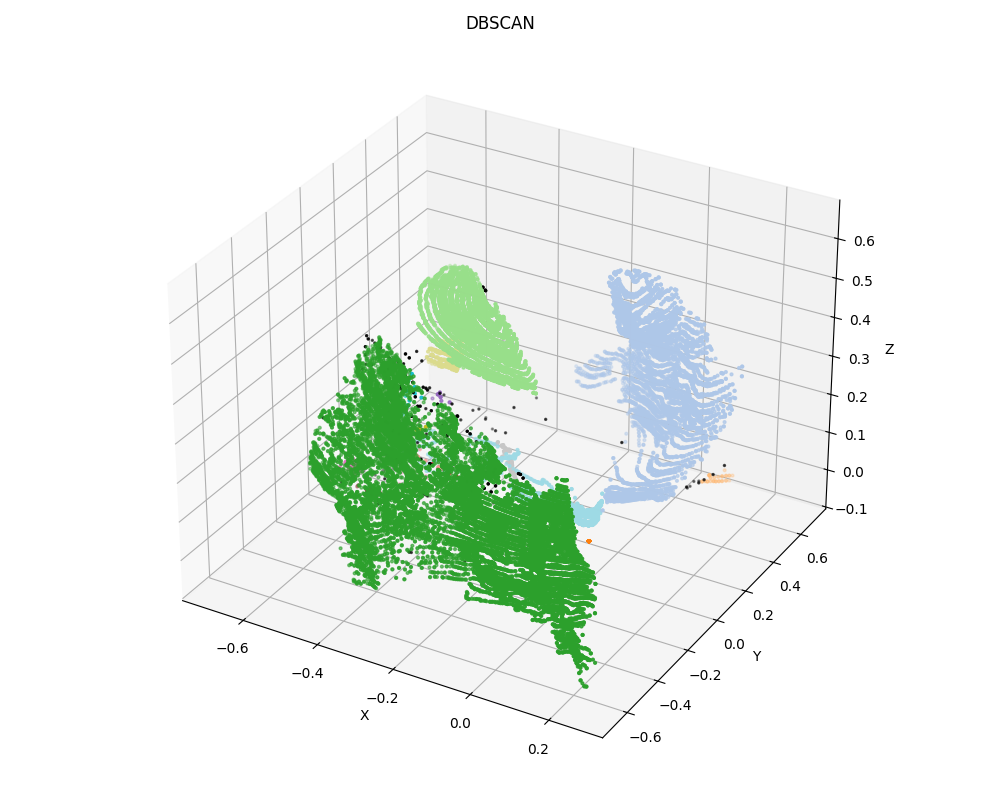

In [13]:
main(pcd_file = r"C:\Users\danag\Documents\LIDAR\data\myself in my room.pcd", eps = 0.04, threshold= 0.05)


C:\Users\danag\AppData\Local\Temp\ipykernel_3884\2928612373.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", len(unique_labels))


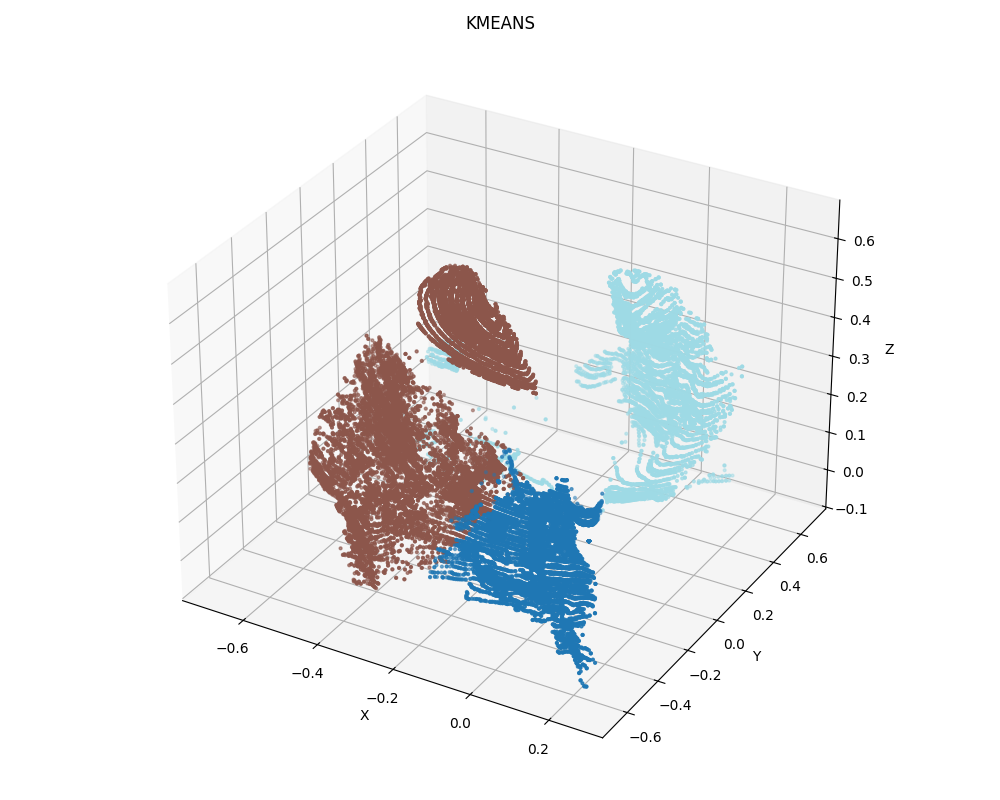

In [14]:
main(pcd_file = r"C:\Users\danag\Documents\LIDAR\data\myself in my room.pcd", cluster = "KMEANS", eps = 0.04, threshold= 0.05)


C:\Users\danag\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  laplacian, dd = csgraph_laplacian(
C:\Users\danag\AppData\Local\Temp\ipykernel_3884\2928612373.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", len(unique_labels))


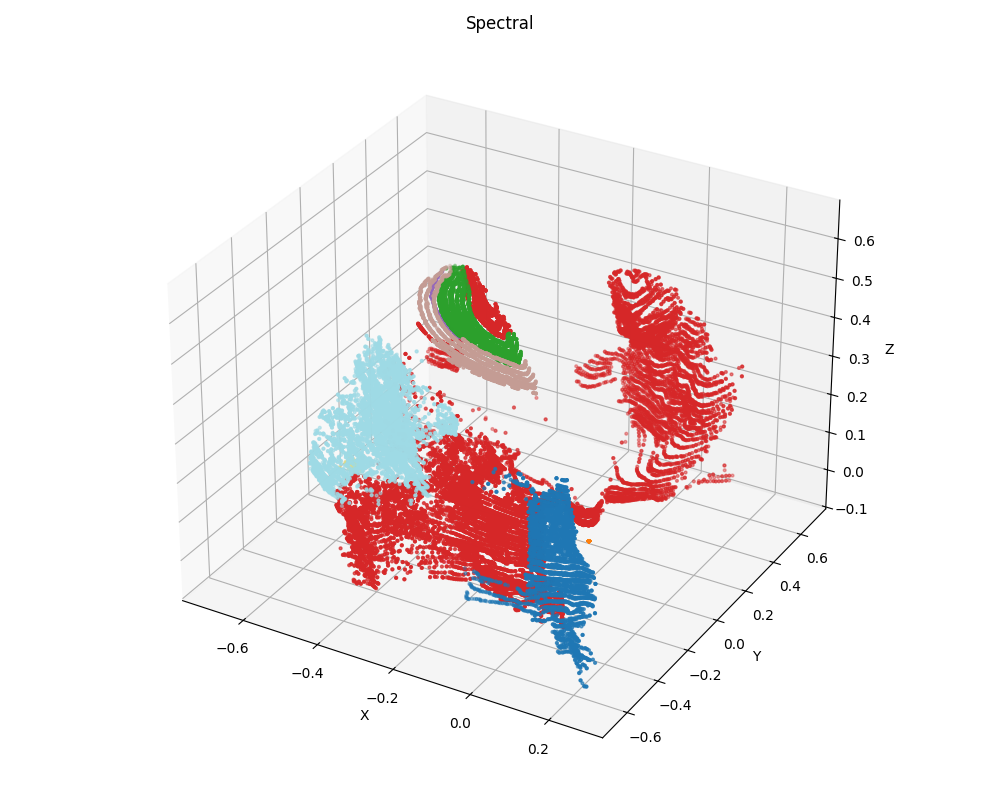

In [15]:
main(pcd_file = r"C:\Users\danag\Documents\LIDAR\data\myself in my room.pcd", cluster = "Spectral", eps = 0.04, threshold= 0.05)


In [16]:
main(pcd_file = r"C:\Users\danag\Documents\LIDAR\data\street-with-wheely-bins.pcd", eps = 0, threshold= 0.2,keep_fraction= 0.4)

InvalidParameterError: The 'eps' parameter of DBSCAN must be a float in the range (0.0, inf). Got 0 instead.

In [ ]:
main(pcd_file = r"C:\Users\danag\Documents\LIDAR\data\myself in my room.pcd", cluster = "HDBSCAN", eps = 0.04, threshold= 0.05)

TypeError: check_array() got an unexpected keyword argument 'ensure_all_finite'. Did you mean 'force_all_finite'?

: 

## Images of gathered data

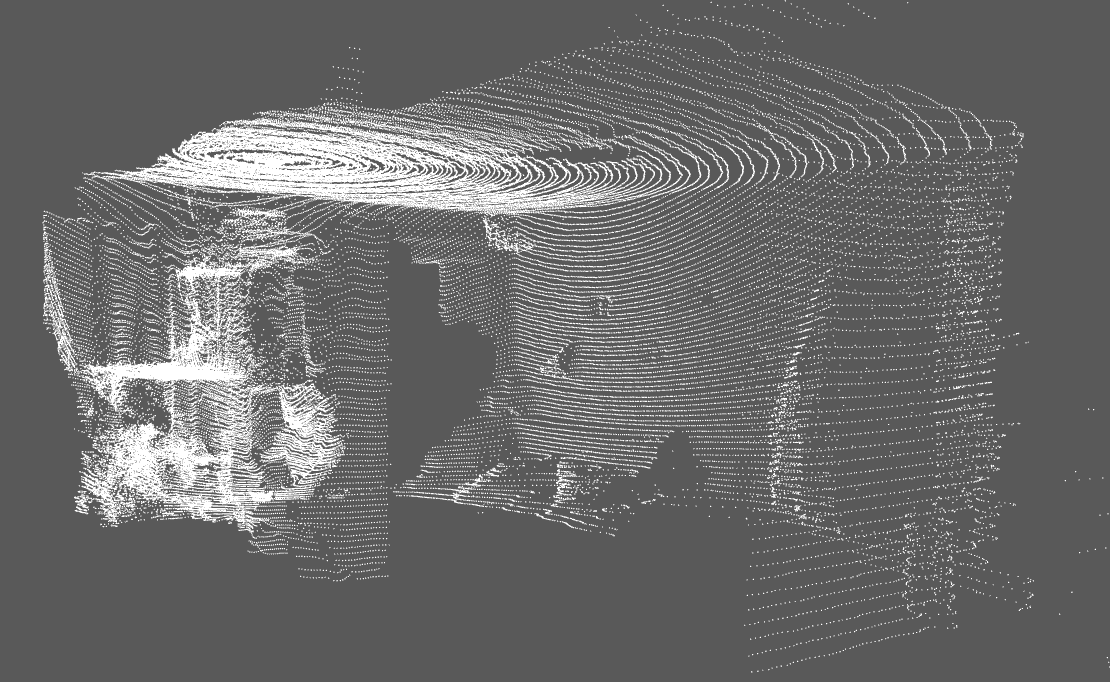